# 26. The Field of Values
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The elliptical range theorem as a shadow. Left: random points on the Bloch sphere $u^2+v^2+z^2=1$, coloured by $z$. Right: their images $\mathrm{tr}(A\rho)=\mu z+\tfrac c2(u+iv)$ for $A=\begin{bmatrix}\mu&c\\0&-\mu\end{bmatrix}$ with $\mu=0.6$, $c=1.6$, filling the ellipse with foci $\pm\mu$ (gold) and semi-axes $\sqrt{\mu^2+c^2/4}$ and $c/2$.

Text(0, 0.5, 'Im')

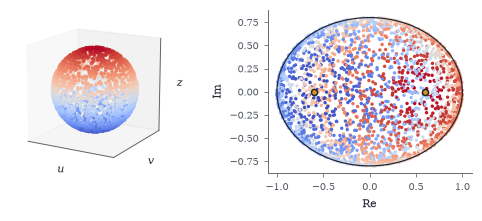

In [2]:
rng = np.random.default_rng(1); Pz = rng.normal(size=(3, 2500)); Pz /= np.linalg.norm(Pz, axis=0); u, v, z = Pz; mu, cc = 0.6, 1.6
img = mu * z + cc / 2 * (u + 1j * v)
fig = plt.figure(figsize=(W, 1.9)); ax1 = fig.add_subplot(1, 2, 1, projection="3d"); ax1.scatter(u, v, z, c=z, cmap="coolwarm", s=1.5); ax1.set_box_aspect((1, 1, 1))
ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_zticks([]); ax1.set_xlabel("$u$", labelpad=-12); ax1.set_ylabel("$v$", labelpad=-12); ax1.set_zlabel("$z$", labelpad=-12); ax1.view_init(15, -60)
ax2 = fig.add_subplot(1, 2, 2); ax2.scatter(img.real, img.imag, c=z, cmap="coolwarm", s=1.5)
tt = np.linspace(0, 2 * np.pi, 200); ax2.plot(np.sqrt(mu**2 + cc**2 / 4) * np.cos(tt), cc / 2 * np.sin(tt), color=INK, lw=0.8); ax2.plot([-mu, mu], [0, 0], "o", color=INK, mfc=GOLD, ms=4, zorder=5)
ax2.set_aspect("equal"); ax2.set_xlabel("Re"); ax2.set_ylabel("Im")

Fields of values (shaded) and eigenvalues (dots), with boundaries computed from the largest eigenvalue of $\mathrm{Re}(e^{-i\theta}A)$ for $360$ angles. Left: a normal matrix; $W(A)$ is the convex hull of the eigenvalues. Middle: a $6\times6$ Jordan block with eigenvalue $0$; $W$ is a disc of radius $\cos(\pi/7)$ although the only eigenvalue is $0$. Right: a triangular matrix with real eigenvalues and a random upper part; $W$ bulges far beyond the segment of eigenvalues. Grey dots are $x^{*}Ax$ for random unit vectors, which crowd towards the interior.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


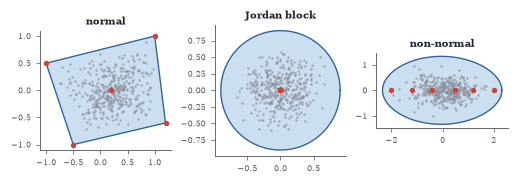

In [3]:
def fov_boundary(A, m=360):
    pts = []
    for th in np.linspace(0, 2 * np.pi, m):
        Hm = (np.exp(-1j * th) * A + np.exp(1j * th) * A.conj().T) / 2; ev, V = np.linalg.eigh(Hm); x = V[:, -1]; pts.append(x.conj() @ A @ x)
    return np.array(pts)
rng = np.random.default_rng(6); Qn, _ = np.linalg.qr(rng.normal(size=(5, 5)) + 1j * rng.normal(size=(5, 5)))
mats = [Qn @ np.diag([1 + 1j, -1 + 0.5j, -0.5 - 1j, 1.2 - 0.6j, 0.2]) @ Qn.conj().T, np.eye(6, k=1).astype(complex), np.diag([2, 1.2, 0.5, -0.4, -1.2, -2.0]) + 0.8 * np.triu(rng.normal(size=(6, 6)), 1)]
fig, axs = plt.subplots(1, 3, figsize=(W, 1.6))
for ax, M, ttl in zip(axs, mats, ["normal", "Jordan block", "non-normal"]):
    bd = fov_boundary(M); ax.fill(bd.real, bd.imag, color=SKY, alpha=0.35); ax.plot(bd.real, bd.imag, color=BLUE, lw=0.8)
    X = rng.normal(size=(M.shape[0], 400)) + 1j * rng.normal(size=(M.shape[0], 400)); X /= np.linalg.norm(X, axis=0)
    q = np.einsum("ik,ij,jk->k", X.conj(), M, X); ax.scatter(q.real, q.imag, s=0.6, color=GRAY, alpha=0.5)
    ev = np.linalg.eigvals(M); ax.plot(ev.real, ev.imag, "o", color=RED, ms=2.5); ax.set_aspect("equal"); ax.set_title(ttl, fontsize=6.5); ax.tick_params(labelsize=5)

Transient growth and the numerical abscissa. For a stable but non-normal $2\times2$ matrix (eigenvalues $-1$ and $-2$, large off-diagonal coupling), $\lVert e^{tA}\rVert$ (blue) first grows, at initial slope $\alpha(A)=\lambda_{\max}(\mathrm{Re}\,A)>0$ (dashed tangent), before decaying at the rate set by the spectral abscissa $-1$ (dotted). Inset: $W(A)$ crosses into the right half-plane although both eigenvalues are in the left.

[]

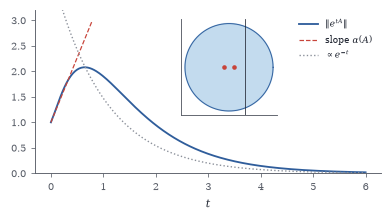

In [4]:
from scipy.linalg import expm
Ast = np.array([[-1.0, 8.0], [0.0, -2.0]]); alpha = np.linalg.eigvalsh((Ast + Ast.T) / 2)[-1]
ts = np.linspace(0, 6, 300); nrm = [np.linalg.norm(expm(t * Ast), 2) for t in ts]
fig, ax = plt.subplots(figsize=(W * 0.75, 1.9))
ax.plot(ts, nrm, color=BLUE, lw=1.2, label=r"$\|e^{tA}\|$"); ax.plot(ts[:40], 1 + alpha * ts[:40], "--", color=RED, lw=0.8, label=r"slope $\alpha(A)$")
ax.plot(ts, 4 * np.exp(-ts), ":", color=GRAY, lw=0.9, label=r"$\propto e^{-t}$"); ax.set_xlabel("$t$"); ax.set_ylim(0, 3.2); ax.legend(fontsize=6, loc="upper right")
ins = ax.inset_axes([0.42, 0.35, 0.28, 0.6]); bd = fov_boundary(Ast.astype(complex)); ins.fill(bd.real, bd.imag, color=SKY, alpha=0.4); ins.plot(bd.real, bd.imag, color=BLUE, lw=0.6)
ins.axvline(0, color=INK, lw=0.5); ins.plot([-1, -2], [0, 0], "o", color=RED, ms=2); ins.set_aspect("equal"); ins.set_xticks([]); ins.set_yticks([])

GMRES on a $200\times200$ non-normal system whose field of values lies in the half-plane $\mathrm{Re}\,z\ge\delta$. The residual (blue) falls faster than Elman's guaranteed rate $(1-\delta^2/\lVert A\rVert^2)^{k/2}$ (dashed), which uses only $\delta$ and $\lVert A\rVert$, two numbers read off from the field of values. The bound is pessimistic, but it is a guarantee that no amount of non-normality can break.

Text(0.5, 1.0, '$\\delta=1.19$, $\\|A\\|=2.84$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


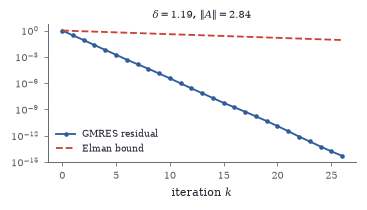

In [5]:
rng = np.random.default_rng(4); n = 200; Ag = 2 * np.eye(n) + 0.5 * rng.normal(size=(n, n)) / np.sqrt(n) + np.triu(rng.normal(size=(n, n)), 1) * 0.03
dlt = np.linalg.eigvalsh((Ag + Ag.T) / 2)[0]; nA = np.linalg.norm(Ag, 2); b = rng.normal(size=n); b /= np.linalg.norm(b)
Vk = [b]; res = [1.0]
for k in range(1, 27):
    w_ = Ag @ Vk[-1]
    for q in Vk: w_ = w_ - (q @ w_) * q
    Vk.append(w_ / np.linalg.norm(w_)); Kb = Ag @ np.array(Vk[:-1]).T
    y, *_ = np.linalg.lstsq(Kb, b, rcond=None); res.append(np.linalg.norm(b - Kb @ y))
fig, ax = plt.subplots(figsize=(W * 0.7, 1.8)); ks = np.arange(27)
ax.semilogy(ks, res, "o-", color=BLUE, ms=2, label="GMRES residual"); ax.semilogy(ks, (1 - dlt**2 / nA**2) ** (ks / 2), "--", color=RED, label="Elman bound")
ax.set_xlabel("iteration $k$"); ax.legend(fontsize=6); ax.set_title(rf"$\delta={dlt:.2f}$, $\|A\|={nA:.2f}$", fontsize=6.5)

In [6]:
rng = np.random.default_rng(2); A5 = rng.normal(size=(5, 5))
wA = max(np.linalg.eigvalsh((np.exp(-1j * t) * A5 + np.exp(1j * t) * A5.T) / 2)[-1] for t in np.linspace(0, 2 * np.pi, 2000))
print(f"rho = {max(abs(np.linalg.eigvals(A5))):.4f}   w = {wA:.4f}   ||A|| = {np.linalg.norm(A5, 2):.4f}   ||A||/2 = {np.linalg.norm(A5, 2)/2:.4f}")

rho = 1.3305   w = 2.2005   ||A|| = 3.5250   ||A||/2 = 1.7625


In [7]:
def wrad(M, m=1500):
    return max(np.linalg.eigvalsh((np.exp(-1j * t) * M + np.exp(1j * t) * M.conj().T) / 2)[-1] for t in np.linspace(0, 2 * np.pi, m))
Aj = np.eye(4, k=1) + 0.3 * np.eye(4); w1 = wrad(Aj)
for k in range(1, 9):
    Ak = np.linalg.matrix_power(Aj, k); print(f"k={k}:  w(A^k)={wrad(Ak):.4f}  <=  w(A)^k={w1**k:.4f}    ||A^k||={np.linalg.norm(Ak, 2):.4f}  <= 2w(A)^k={2*w1**k:.4f}")

k=1:  w(A^k)=1.1090  <=  w(A)^k=1.1090    ||A^k||=1.2375  <= 2w(A)^k=2.2180
k=2:  w(A^k)=1.0539  <=  w(A)^k=1.2299    ||A^k||=1.4789  <= 2w(A)^k=2.4598
k=3:  w(A^k)=0.9573  <=  w(A)^k=1.3640    ||A^k||=1.6415  <= 2w(A)^k=2.7280
k=4:  w(A^k)=0.7588  <=  w(A)^k=1.5127    ||A^k||=1.4294  <= 2w(A)^k=3.0254
k=5:  w(A^k)=0.5026  <=  w(A)^k=1.6776    ||A^k||=0.9794  <= 2w(A)^k=3.3552
k=6:  w(A^k)=0.2873  <=  w(A)^k=1.8605    ||A^k||=0.5671  <= 2w(A)^k=3.7210
k=7:  w(A^k)=0.1474  <=  w(A)^k=2.0633    ||A^k||=0.2926  <= 2w(A)^k=4.1266
k=8:  w(A^k)=0.0699  <=  w(A)^k=2.2883    ||A^k||=0.1391  <= 2w(A)^k=4.5765
